<div style="background:#0B1F4B;padding:22px 26px;border-radius:12px;border:3px solid #C9A227;font-family:'Times New Roman',serif">
<img src="https://raw.githubusercontent.com/drssnaiml1-cell/26UAMPC204-Artificial-Intelligence/main/assets/logo.png" alt="Sanjivani University" width="92" style="float:right;background:#FFFFFF;border:2px solid #C9A227;border-radius:8px;padding:3px;margin-left:14px">
<div style="color:#C9A227;font-size:14px;letter-spacing:2px;font-weight:bold">26UAMPC204 · ARTIFICIAL INTELLIGENCE LAB · SANJIVANI UNIVERSITY</div>
<div style="color:#FFFFFF;font-size:30px;font-weight:bold;margin-top:6px">Experiment 6: Facts, Rules and Logical Inference</div>
<div style="color:#F6EBC8;font-size:15px;margin-top:8px"><b>Course Outcome:</b> CO204.3 &nbsp;|&nbsp; <b>Faculty:</b> Dr. S. Satyanarayana, Professor &amp; Advisor, AI &amp; DS</div>
<div style="clear:both"></div></div>

<div style="background:#F6EBC8;padding:12px 18px;border-radius:8px;margin-top:10px;font-family:'Times New Roman',serif;color:#0B1F4B">
<b>🎯 Aim:</b> Represent facts and rules in a knowledge base (Prolog-style, in Python) and answer queries using forward chaining and backward chaining, including a propositional truth-table entailment checker.</div>

## 📘 Theory

A **knowledge base** stores facts (ground atoms) and rules (Horn clauses $p_1\wedge\dots\wedge p_n\Rightarrow q$).
**Forward chaining** fires rules whose premises are satisfied until no new facts appear (data-driven).
**Backward chaining** starts from the query and recursively proves the rule premises (goal-driven, as in Prolog).
**Model checking** decides $KB\models\alpha$ by enumerating all truth assignments.

## 🧭 Algorithm

1. Store facts as tuples, e.g. ('parent', 'ram', 'sita'); rules as (head, [body literals]) with variables starting with '?'.
2. Forward chaining: repeatedly unify rule bodies with known facts and add instantiated heads.
3. Backward chaining: to prove a goal, unify it with a fact or a rule head and prove the body recursively.
4. Print the derived facts, query answers and proof traces.

## ⚙️ Setup

In [1]:
# ---- Course style (navy & gold, Times) -------------------------------------
import os, warnings
warnings.filterwarnings("ignore")
import numpy as np
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib import animation
from IPython.display import Image, display

NAVY, NAVY2, GOLD, GOLDL = "#0B1F4B", "#1F3A7A", "#C9A227", "#F6EBC8"
TEAL, CRIMSON, LEAF, MIST, SLATE = "#0E7C86", "#A4243B", "#2E7D32", "#EEF2F8", "#4A5568"
plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman", "Liberation Serif", "DejaVu Serif"],
    "axes.edgecolor": SLATE, "axes.titleweight": "bold", "axes.titlecolor": NAVY,
    "axes.titlesize": 14, "axes.labelcolor": NAVY, "figure.dpi": 110,
    "axes.spines.top": False, "axes.spines.right": False,
})
FIG = os.path.join("..", "assets", "figures");    os.makedirs(FIG, exist_ok=True)
ANI = os.path.join("..", "assets", "animations"); os.makedirs(ANI, exist_ok=True)

def save_gif(anim, name, fps=2):
    path = os.path.join(ANI, name)
    anim.save(path, writer=animation.PillowWriter(fps=fps))
    plt.close("all")
    return path
print("Environment ready  ✓  numpy", np.__version__, "| matplotlib", matplotlib.__version__)


Environment ready  ✓  numpy 2.5.3 | matplotlib 3.11.2


## 💻 Implementation and Output

In [2]:
import itertools
FACTS = {("parent","dashrath","ram"), ("parent","dashrath","bharat"), ("parent","ram","luv"), ("parent","ram","kush"),
         ("parent","kaushalya","ram"), ("male","dashrath"), ("male","ram"), ("male","bharat"), ("male","luv"), ("male","kush"),
         ("female","kaushalya"), ("female","sita"), ("parent","sita","luv"), ("parent","sita","kush")}
RULES = [
  (("father","?x","?y"),      [("parent","?x","?y"), ("male","?x")]),
  (("mother","?x","?y"),      [("parent","?x","?y"), ("female","?x")]),
  (("grandparent","?x","?z"), [("parent","?x","?y"), ("parent","?y","?z")]),
  (("sibling","?x","?y"),     [("parent","?p","?x"), ("parent","?p","?y"), ("neq","?x","?y")]),
  (("uncle","?u","?c"),       [("parent","?p","?c"), ("sibling","?u","?p"), ("male","?u")]),
]
def is_var(t): return isinstance(t, str) and t.startswith("?")
def walk(t, th):
    while is_var(t) and t in th: t = th[t]
    return t
def subst(lit, th): return tuple(walk(t, th) for t in lit)
def match(pat, fact, th):
    if len(pat) != len(fact): return None
    th = dict(th)
    for p, f in zip(pat, fact):
        p = th.get(p, p)
        if is_var(p): th[p] = f
        elif p != f: return None
    return th
print(f"KB: {len(FACTS)} facts, {len(RULES)} rules")

KB: 14 facts, 5 rules


### Forward chaining (data-driven)

In [3]:
def forward_chain(facts, rules, verbose=True):
    facts = set(facts); rnd = 0; history = []
    while True:
        rnd += 1; new = set()
        for head, body in rules:
            def sat(i, th):
                if i == len(body): yield th; return
                lit = subst(body[i], th)
                if lit[0] == "neq":
                    if lit[1] != lit[2]: yield from sat(i + 1, th)
                    return
                for f in facts:
                    t2 = match(lit, f, th)
                    if t2 is not None: yield from sat(i + 1, t2)
            for th in sat(0, {}):
                h = subst(head, th)
                if h not in facts: new.add(h)
        if not new: break
        history.append((rnd, sorted(new))); facts |= new
        if verbose: print(f"Round {rnd}: +{len(new)} facts →", ", ".join(f"{p}({', '.join(a)})" for p, *a in sorted(new)))
    return facts, history
ALL, hist = forward_chain(FACTS, RULES)
print("\nGrandparents of luv:", sorted(f[1] for f in ALL if f[0] == "grandparent" and f[2] == "luv"))
print("Uncle of luv       :", sorted(f[1] for f in ALL if f[0] == "uncle" and f[2] == "luv"))

Round 1: +15 facts → father(dashrath, bharat), father(dashrath, ram), father(ram, kush), father(ram, luv), grandparent(dashrath, kush), grandparent(dashrath, luv), grandparent(kaushalya, kush), grandparent(kaushalya, luv), mother(kaushalya, ram), mother(sita, kush), mother(sita, luv), sibling(bharat, ram), sibling(kush, luv), sibling(luv, kush), sibling(ram, bharat)
Round 2: +2 facts → uncle(bharat, kush), uncle(bharat, luv)

Grandparents of luv: ['dashrath', 'kaushalya']
Uncle of luv       : ['bharat']


### Backward chaining (goal-driven, Prolog style) with proof trace

In [4]:
counter = itertools.count()
def rename(rule):
    k = next(counter); ren = lambda l: tuple(f"{t}_{k}" if is_var(t) else t for t in l)
    return ren(rule[0]), [ren(b) for b in rule[1]]
def bc(goals, th, depth=0, trace=None):
    if not goals: yield th; return
    g = subst(goals[0], th); rest = goals[1:]
    if g[0] == "neq":
        if g[1] != g[2]: yield from bc(rest, th, depth, trace)
        return
    for f in sorted(FACTS):
        t2 = match(g, f, th)
        if t2 is not None:
            if trace is not None: trace.append("  " * depth + f"✓ fact {f[0]}({', '.join(f[1:])})")
            yield from bc(rest, t2, depth, trace)
    for rule in RULES:
        head, body = rename(rule)
        # unify the renamed rule head with the goal
        t2 = dict(th); ok = True
        for a, b in zip(head, g):
            a, b = walk(a, t2), walk(b, t2)
            if a == b: continue
            if is_var(a): t2[a] = b
            elif is_var(b): t2[b] = a
            else: ok = False; break
        if ok and len(head) == len(g):
            if trace is not None: trace.append("  " * depth + f"→ try rule {rule[0][0]} for {g[0]}({', '.join(g[1:])})")
            yield from bc(body + rest, t2, depth + 1, trace)
def ask(q):
    tr = []; sols = []
    for th in bc([q], {}, 0, tr):
        sols.append(subst(q, th)); break
    return sols, tr
for q in [("grandparent","dashrath","kush"), ("uncle","bharat","luv"), ("mother","sita","kush"), ("father","bharat","luv")]:
    s, tr = ask(q)
    print(f"?- {q[0]}({', '.join(q[1:])}).  →  {'YES' if s else 'NO'}")
s, tr = ask(("uncle","bharat","luv")); print("\nProof trace for uncle(bharat, luv):"); print("\n".join(tr[:14]))

?- grandparent(dashrath, kush).  →  YES
?- uncle(bharat, luv).  →  YES
?- mother(sita, kush).  →  YES
?- father(bharat, luv).  →  NO

Proof trace for uncle(bharat, luv):
→ try rule uncle for uncle(bharat, luv)
  ✓ fact parent(ram, luv)
  → try rule sibling for sibling(bharat, ram)
    ✓ fact parent(dashrath, bharat)
    ✓ fact parent(dashrath, ram)
    ✓ fact male(bharat)


### Propositional entailment by truth-table model checking

In [5]:
import pandas as pd
syms = ["P", "Q", "R"]
KB    = lambda m: (not m["P"] or m["Q"]) and (not m["Q"] or m["R"]) and m["P"]   # P⇒Q, Q⇒R, P
alpha = lambda m: m["R"]
rows = []
for vals in itertools.product([False, True], repeat=3):
    m = dict(zip(syms, vals)); rows.append({**{k: "T" if v else "F" for k, v in m.items()}, "KB": "T" if KB(m) else "F", "alpha": "T" if alpha(m) else "F"})
df = pd.DataFrame(rows); df.columns = ["P", "Q", "R", "KB", "α = R"]; print(df.to_string(index=False))
entails = all(alpha(dict(zip(syms, v))) for v in itertools.product([False, True], repeat=3) if KB(dict(zip(syms, v))))
print("\nKB ⊨ R ?", entails)

P Q R KB α = R
F F F  F     F
F F T  F     T
F T F  F     F
F T T  F     T
T F F  F     F
T F T  F     T
T T F  F     F
T T T  T     T

KB ⊨ R ? True


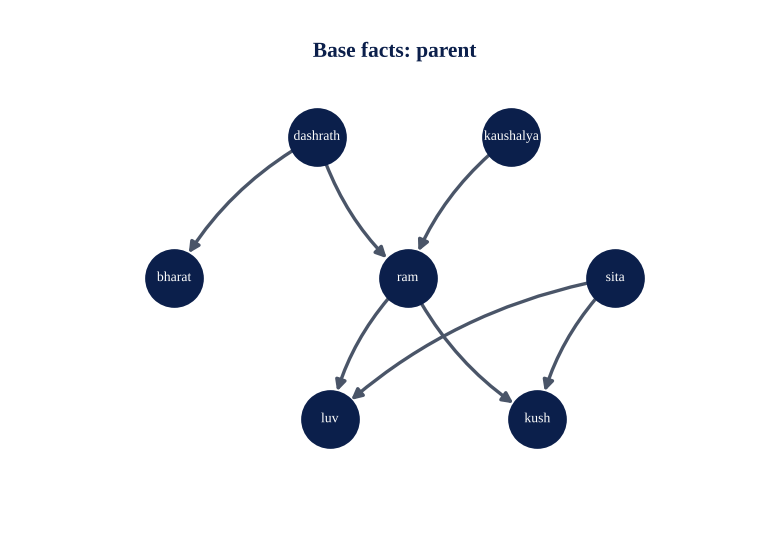

In [6]:
import networkx as nx
G = nx.DiGraph(); base = [f for f in FACTS if f[0] == "parent"]
for f in base: G.add_edge(f[1], f[2], kind="parent")
for f in ALL:
    if f[0] in ("grandparent", "uncle"): G.add_edge(f[1], f[2], kind=f[0])
pos = {"dashrath": (0.5, 2), "kaushalya": (2, 2), "ram": (1.2, 1), "bharat": (-0.6, 1), "sita": (2.8, 1), "luv": (0.6, 0), "kush": (2.2, 0)}
fig, ax = plt.subplots(figsize=(7, 5))
def drawkb(k):
    ax.clear(); kinds = ["parent"] + (["grandparent"] if k >= 1 else []) + (["uncle"] if k >= 2 else [])
    cmap = {"parent": SLATE, "grandparent": GOLD, "uncle": CRIMSON}
    es = [(u, v) for u, v, d in G.edges(data=True) if d["kind"] in kinds]
    nx.draw_networkx_nodes(G, pos, ax=ax, node_color=NAVY, node_size=1400)
    nx.draw_networkx_labels(G, pos, ax=ax, font_color="white", font_family="serif", font_size=9)
    nx.draw_networkx_edges(G, pos, ax=ax, edgelist=es, edge_color=[cmap[G[u][v]["kind"]] for u, v in es], width=2.2, arrowsize=14,
                           connectionstyle="arc3,rad=0.15", node_size=1400)
    ax.set_xlim(-1.2, 3.4); ax.set_ylim(-0.5, 2.5)
    ax.set_title(["Base facts: parent", "Forward chaining adds grandparent (gold)", "…then uncle (crimson)"][min(k, 2)]); ax.axis("off")
gif = save_gif(animation.FuncAnimation(fig, drawkb, frames=4), "exp06_forward_chaining.gif", fps=0.8)
display(Image(filename=gif))

## ✅ Result and Conclusion

<div style="border-left:6px solid #2E7D32;background:#E3F2E4;padding:12px 18px;border-radius:6px;font-family:'Times New Roman',serif;color:#1A202C">
<b style="color:#2E7D32">Conclusion</b><br>Forward chaining derived all father, mother, grandparent, sibling and uncle relations in a few rounds; backward chaining answered individual queries with an explicit proof trace; model checking confirmed that {P⇒Q, Q⇒R, P} entails R.</div>

## 🎤 Viva Questions

1. Differentiate forward and backward chaining.
2. What is a Horn clause and why is it important for chaining?
3. How does Prolog implement backward chaining?
4. What is the complexity of truth-table model checking?
5. Why did we need the 'neq' built-in in the sibling rule?